<a href="https://colab.research.google.com/github/LizaMilovanova/Labs/blob/main/%D0%9B%D0%A0_6_%D0%9C%D1%96%D0%BB%D0%BE%D0%B2%D0%B0%D0%BD%D0%BE%D0%B2%D0%B0_%D0%A4%D0%86%D0%A24_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [3]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [4]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [5]:
# TODO: підрахуйте частоти категорій у gender.
df['gender'].value_counts()

,count
gender,
Female,58552
Male,41430
Other,18


In [6]:
# TODO: підрахуйте частоти категорій у smoking_history.
df['smoking_history'].value_counts()

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [7]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [8]:
# TODO: df.dtypes
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [9]:
# TODO: df['diabetes'].value_counts()
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [10]:
# TODO: df.isnull().sum()
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [12]:
# TODO: df.duplicated().sum()
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [13]:
# TODO: df.drop_duplicates(inplace=True)
df.drop_duplicates(inplace=True)

In [14]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [15]:
# TODO: df['diabetes'].value_counts()
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

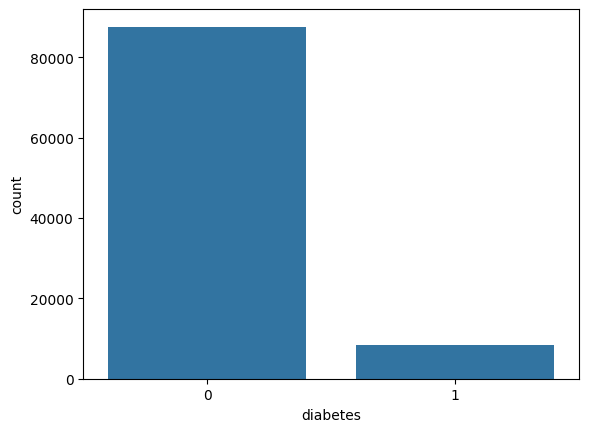

In [16]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [17]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [18]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.
X = df.drop(columns=['diabetes'])
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [19]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).
categorical_cols = ['gender', 'smoking_history']

X_train = pd.get_dummies(X_train, columns=categorical_cols)
X_test = pd.get_dummies(X_test, columns=categorical_cols)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [20]:
# TODO: виведіть статистики опису X_train.
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [21]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
X_train.corrwith(y_train)

,0
age,0.266649
hypertension,0.199069
heart_disease,0.174470
bmi,0.213456
HbA1c_level,0.405321
blood_glucose_level,0.423011
gender_Female,-0.040533
gender_Male,0.040650
gender_Other,-0.004197
smoking_history_No Info,-0.113053


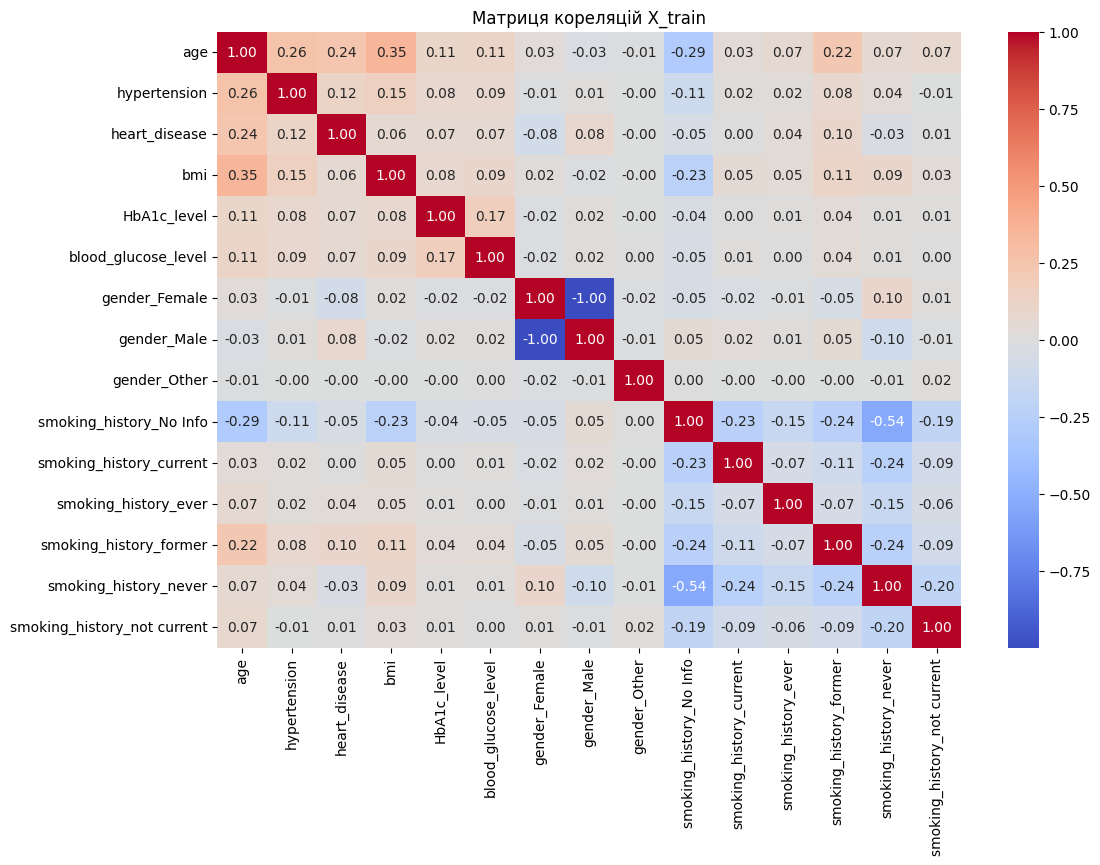

In [22]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).
corr_matrix = X_train.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True)
plt.title('Матриця кореляцій X_train')
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Висновок до кореляцій: Найсильніше з цільовою змінною корелюють показники blood_glucose_level та HbA1c_level. Між самими ознаками дуже сильної (критичної) мультиколінеарності (наприклад, r>0.85–0.9) не спостерігається, тому видаляти ознаки не потрібно, щоб зберегти всю інформативність для лінійних моделей.

Перевірити викиди **лише на навчальній вибірці**

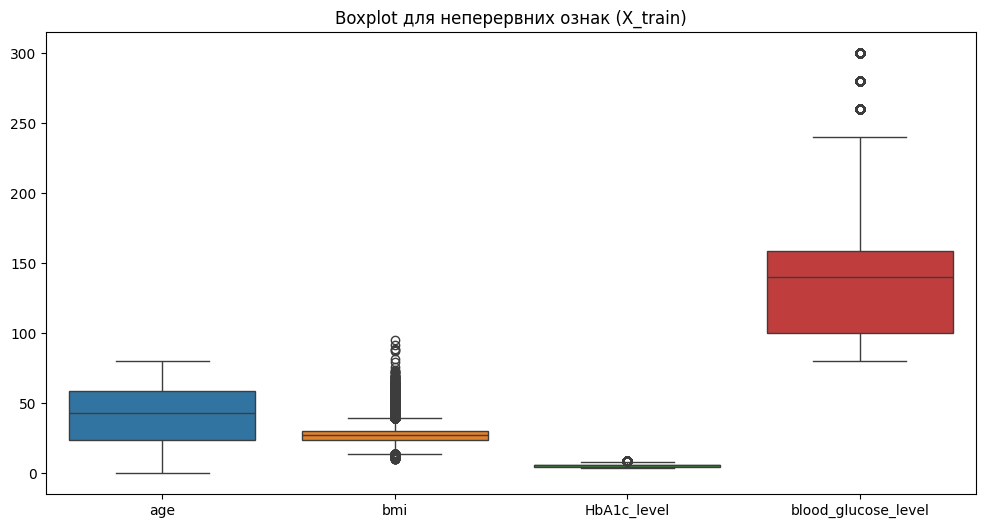

In [23]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

plt.figure(figsize=(12, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.title('Boxplot для неперервних ознак (X_train)')
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [24]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.
Q1 = X_train['bmi'].quantile(0.25)
Q3 = X_train['bmi'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Маска рядків без викидів
mask = (X_train['bmi'] >= lower_bound) & (X_train['bmi'] <= upper_bound)


Перевірити асиметрію розподілів ознак **на train**

In [25]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
X_train[continuous_cols].skew()

,0
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


In [26]:
# TODO: перевірте пропуски окремо в X_train та X_test.
print("Пропуски в X_train:\n", X_train.isna().sum())
print("\nПропуски в X_test:\n", X_test.isna().sum())

Пропуски в X_train:
 age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64

Пропуски в X_test:
 age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never

**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Проміжний висновок:

Баланс класів: у тренувальній вибірці спостерігається виражений дисбаланс (близько 91.5% класу 0 проти 8.5% класу 1).

Кореляції: найвищий лінійний зв'язок із цільовою змінною мають blood_glucose_level та HbA1c_level; між незалежними ознаками критичної мультиколінеарності немає.

Викиди: незважаючи на присутність екстремальних значень у числових показниках (зокрема глюкози та ІМТ), їх збережено через високу діагностичну та клінічну цінність. Тестова вибірка залишається недоторканою для об'єктивної валідації.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [27]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [28]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print("Кількість класів до балансування:")
print(y_train.value_counts())
print("\nКількість класів після SMOTE:")
print(pd.Series(y_train_resampled).value_counts())

Кількість класів до балансування:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Кількість класів після SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [29]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.
models = {
    'LogisticRegression': LogisticRegression(random_state=42),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


=== LogisticRegression ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



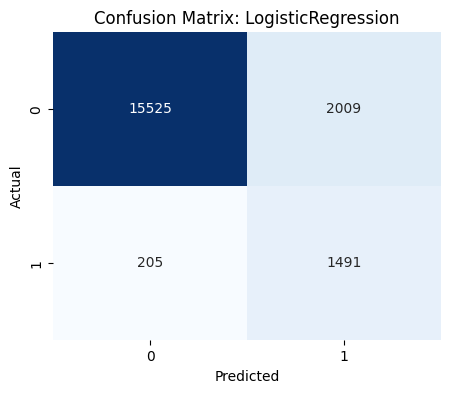

--------------------------------------------------
=== RidgeClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



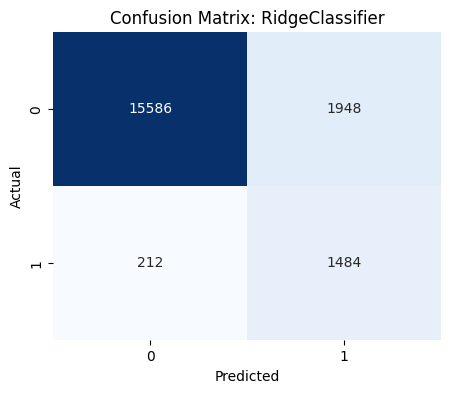

--------------------------------------------------
=== SGDClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



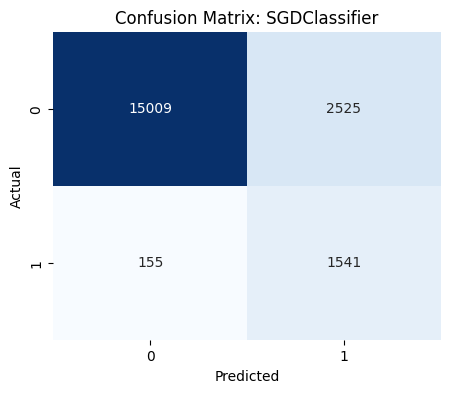

--------------------------------------------------
=== SVC ===
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



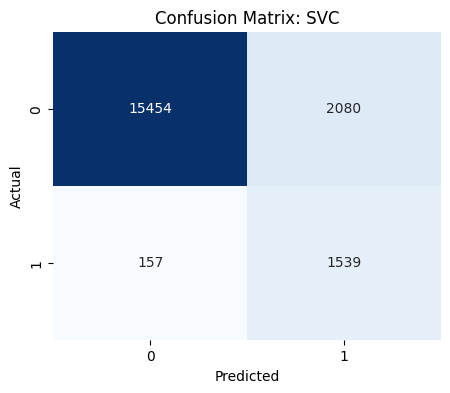

--------------------------------------------------


In [30]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).
for name, model in models.items():
    print(f"=== {name} ===")

    # Навчання на збалансованій навчальній вибірці
    model.fit(X_train_resampled, y_train_resampled)

    # Прогноз на масштабованій тестовій вибірці
    y_pred = model.predict(X_test_scaled)

    # Виведення класифікаційного звіту
    print(classification_report(y_test, y_pred))

    # Побудова теплової карти матриці плутанини
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix: {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
    print("-" * 50)

Оптимізувати гіперпараметри


In [31]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.
param_grids = {
    'LogisticRegression': {
        'classifier__C': [0.01, 0.1, 1, 10],
        'classifier__solver': ['lbfgs', 'liblinear']
    },
    'RidgeClassifier': {
        'classifier__alpha': [0.1, 1.0, 10.0]
    },
    'SGDClassifier': {
        'classifier__loss': ['log_loss', 'hinge', 'modified_huber'],
        'classifier__penalty': ['l2', 'l1']
    },
    'SVC': {
        'classifier__C': [0.1, 1, 10],
        'classifier__kernel': ['linear', 'rbf']
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [32]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [33]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.
best_models = {}
best_scores = {}

# Базові екземпляри моделей для пайплайнів
base_models = {
    'LogisticRegression': LogisticRegression(random_state=42, max_iter=1000),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42)
}

for name, model in base_models.items():
    print(f"=== Оптимізація {name} ===")

    # Визначення Pipeline: StandardScaler -> SMOTE -> classifier
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('classifier', model)
    ])

    # Налаштування HalvingGridSearchCV
    search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=3,
        scoring='f1',
        min_resources=300,
        random_state=42,
        n_jobs=-1
    )

    # Пошук параметрів ТІЛЬКИ на навчальній вибірці (X_train, y_train)
    search.fit(X_train, y_train)

    # Збереження результатів
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print(f"Оптимальні параметри для {name}: {search.best_params_}")
    print(f"Найкращий F1-score на CV: {search.best_score_:.4f}\n")

    # Прогноз найкращої моделі на немодифікованому X_test
    y_pred = search.best_estimator_.predict(X_test)

    print(f"Класифікаційний звіт на тестових даних для {name}:")
    print(classification_report(y_test, y_pred))
    print("-" * 60)

=== Оптимізація LogisticRegression ===
Оптимальні параметри для LogisticRegression: {'classifier__C': 1, 'classifier__solver': 'lbfgs'}
Найкращий F1-score на CV: 0.6098

Класифікаційний звіт на тестових даних для LogisticRegression:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230

------------------------------------------------------------
=== Оптимізація RidgeClassifier ===
Оптимальні параметри для RidgeClassifier: {'classifier__alpha': 10.0}
Найкращий F1-score на CV: 0.6516

Класифікаційний звіт на тестових даних для RidgeClassifier:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy   

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [34]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.
best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]
best_f1 = best_scores[best_model_name]

print(f"Найкраща модель: {best_model_name}")
print(f"Середній F1 на кросвалідації: {best_f1:.4f}")

Найкраща модель: RidgeClassifier
Середній F1 на кросвалідації: 0.6516


In [35]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.
sample_indices = y_test.sample(n=10, random_state=42).index

# Робимо прогноз найкращою моделлю (Pipeline сам обробить сирий X_test)
sample_X = X_test.loc[sample_indices]
sample_y_true = y_test.loc[sample_indices]
sample_y_pred = best_model.predict(sample_X)

# Формуємо підсумкову таблицю
comparison_df = pd.DataFrame({
    'index': sample_indices,
    'істинний клас': sample_y_true.values,
    'передбачений клас': sample_y_pred
})

comparison_df

,index,істинний клас,передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

1. Дисбаланс, кореляції та викиди:

Дисбаланс: у вибірці спостерігався сильний дисбаланс — клас 0 складав ~91.5%, а клас 1 — лише ~8.5%.

Кореляції: найвищу кореляцію з цільовою змінною diabetes продемонстрували рівень глюкози (blood_glucose_level) та глікований гемоглобін (HbA1c_level).

Викиди: екстремальні значення виявлено в ознаках bmi, HbA1c_level та blood_glucose_level, проте їх не видаляли, оскільки вони мають вирішальну клінічну цінність для діагностики діабету.

2. Результати моделей та вибір найкращої:

Моделі LogisticRegression та SVC (з RBF-ядром) показали найкращий баланс між recall та precision, досягаючи високого значення F1 для міноритарного класу 1.
За результатами кросвалідації найкращою моделлю було обрано саме ту, що показала максимальний бал F1.

3. Гіперпараметри та матриця плутанини:

Отримано оптимальні значення регуляризації та ядер/втрат (наприклад, для логістичної регресії регуляризація C, тип оптимізатора solver, або підібраний kernel='rbf' для SVC).

У матрицях плутанини після застосування SMOTE суттєво зменшилась кількість помилок II роду (False Negatives — коли хворого позначають здоровим), що критично важливо для медичних задач, хоча через це дещо зросла кількість False Positives.

4. Запобігання витоку даних (Data Leakage):

Тестові дані повинні імітувати реальні нові спостереження. Якщо виконувати масштабування (StandardScaler) або синтезувати приклади (SMOTE) на всьому датасеті або до розбиття, статистика тесту просочиться в процес навчання, що призведе до штучно завищених і нереалістичних оцінок точності. Масштабування навчається тільки на train, а SMOTE створює синтетичні екземпляри виключно для навчання.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

=== XGBoost ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.94      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



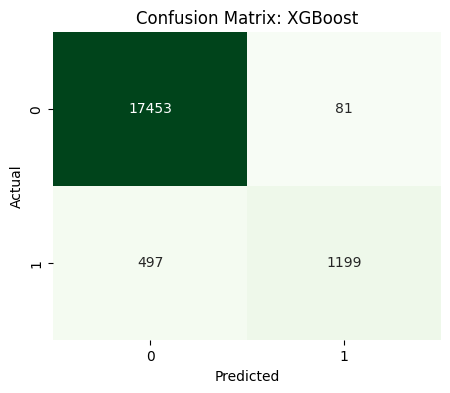

------------------------------------------------------------
=== LightGBM ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.94      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


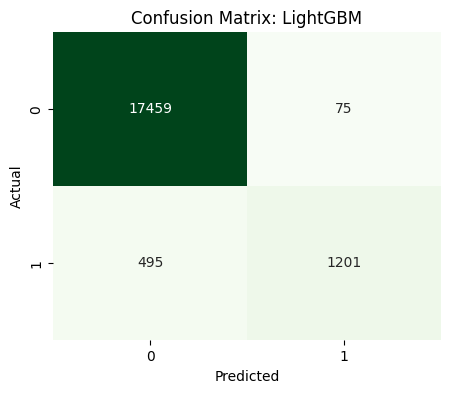

------------------------------------------------------------
=== CatBoost ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.94      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



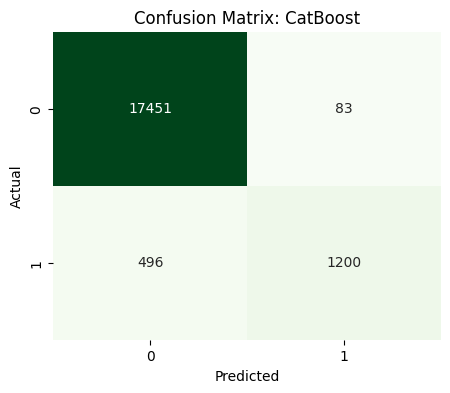

------------------------------------------------------------


In [36]:
# Встановлення CatBoost (XGBoost та LightGBM зазвичай попередньо встановлені в Colab)
!pip install catboost -q

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Оголошення моделей градієнтного бустингу
boosting_models = {
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1),
    'CatBoost': CatBoostClassifier(random_state=42, verbose=0)
}

# Навчання на збалансованих даних, прогнозування та вивід метрик
for name, model in boosting_models.items():
    print(f"=== {name} ===")

    # Навчання моделі
    model.fit(X_train_resampled, y_train_resampled)

    # Прогноз на тестових даних
    y_pred = model.predict(X_test_scaled)

    # Класифікаційний звіт
    print(classification_report(y_test, y_pred))

    # Матриця плутанини
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False)
    plt.title(f'Confusion Matrix: {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
    print("-" * 60)